In [ ]:
ele_alınanlar={1:"data (prepare and load)",
               2:"build model",
               3:"fitting the model to data(training)",
               4:"making predictions and evulating a model ( inference )",
               5:"saving and loading a model",
               6:"putting it all together"}

ele_alınanlar


{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data(training)',
 4: 'making predictions and evulating a model ( inference )',
 5: 'saving and loading a model',
 6: 'putting it all together'}

In [ ]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__


'2.11.0+cpu'

In [ ]:
weight=0.7
bias=0.3


start=0
end=1
step=0.02

X=torch.arange(start,end,step).unsqueeze(dim=1)
Y=weight*X+bias

X[:10],Y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [ ]:
len(X),len(Y)

(50, 50)

In [ ]:
train_split=int(0.8*len(X))
X_train,Y_train=X[:train_split],Y[:train_split]
X_test,Y_test=X[train_split:],Y[train_split:]

len(X_train),len(Y_train),len(X_test),len(Y_test)


(40, 40, 10, 10)

/tmp/ipykernel_2729/4280746043.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(prop={"size":14});


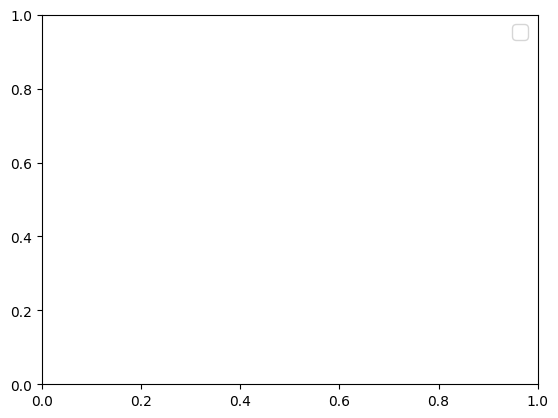

In [ ]:
def plot_predictions(train_data=X_train,
                     train_labels=Y_train,
                     test_data=X_test,
                     test_labels=Y_test,
                            predictions=None):
  """
  plots training data,test data and compares predictions

  """
  plt.figure(figsize=(10,7))

#Plot training data in BLUE
  plt.scatter(train_data,train_labels,
              c="b",s=4,label="Training data")




#plot test data in GREEN
  plt.scatter(test_data, test_labels,
            c="g",s=4,label="Testing data")



#Are there predictions
  if predictions is not None:
    plt.scatter(test_data,predictions, c="r", s=4, label="Predictions")


plt.legend(prop={"size":14});



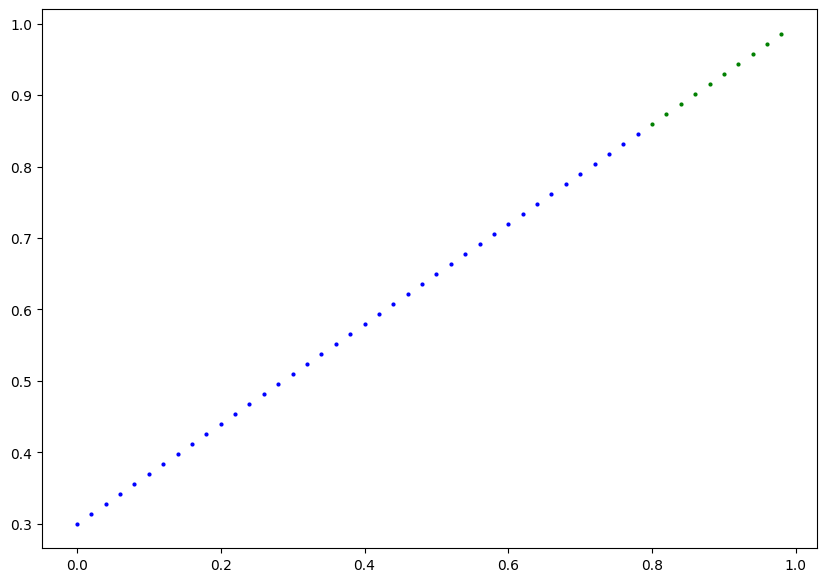

In [ ]:
plot_predictions();

###Build model

In [ ]:
#Create a linear regression model class
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()#--->nn.module altyapısını başlatır.
    self.weights=nn.Parameter(torch.randn(1,
                                         requires_grad=True,
                                         dtype=torch.float))
    self.bias=nn.Parameter(torch.randn(1,
                                      requires_grad=True,
                                      dtype=float))

  def forward(self, x: torch.Tensor)-> torch.Tensor:#<- "x" is the input data
   return self.weights * x + self.bias # This is the linear regression formula

### Pytorch model building essentials

* torch.nn
* torch.nn.Parameter
* torch.nn.Module
* torch.optim
* def forward()

### Checking the contents of our PyTorch model

In [ ]:
torch.manual_seed(42)

model_0=LinearRegressionModel()

list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], dtype=torch.float64, requires_grad=True)]

In [ ]:
#List named parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])),
             ('bias', tensor([0.1288], dtype=torch.float64))])

In [ ]:
weight,bias

(0.7, 0.3)

In [ ]:
with torch.inference_mode():
  Y_preds=model_0(X_test)

#with torch.no_grad():
 #Y_preds=model_0(X_test)
Y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]], dtype=torch.float64)

In [ ]:
Y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

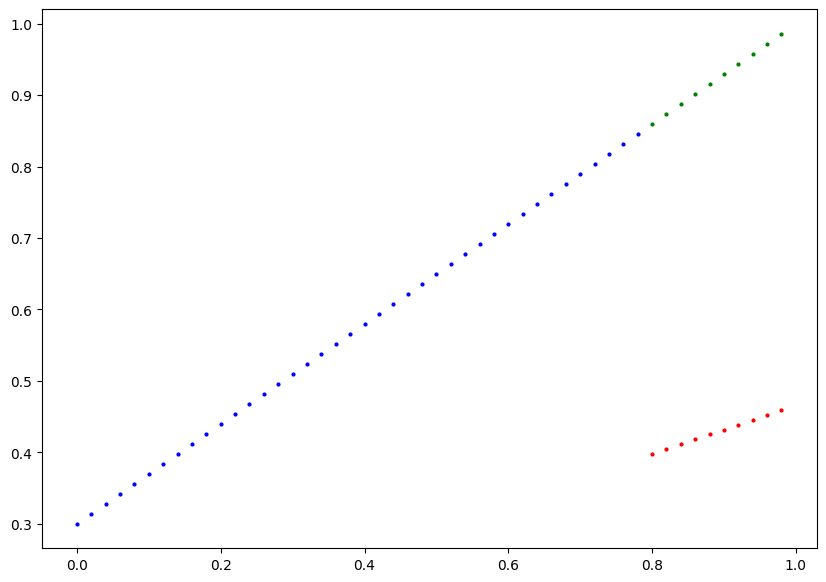

In [ ]:
plot_predictions(predictions=Y_preds)

###Train Model

* **Loss Function:**A function to measure how wrong your model's predictions are to the ideal outputs,lower is better.(Modelin hata oranını gösterir)(düşük değer=daha iyidir.)

* **Optimizer:**Takes into account the loss of a model and adjusts the model's parameters(e.g. weight & bias) to improve the loss function.

And specifically for PyTorch, we need

* A training loop
* A testing loop

In [ ]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], dtype=torch.float64, requires_grad=True)]

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])),
             ('bias', tensor([0.1288], dtype=torch.float64))])

In [ ]:
loss_fn = nn.L1Loss()

#-> SGD Modelin tahminleri yanlış yaptığında, SGD weights ve bias değerlerini hatayı azaltacak yönde günceller.
optimizer=torch.optim.SGD (params=model_0.parameters(),
                           lr=0.01)# lr=learning rate

### Building a training loop (and a testing loop) in PyTorch

0- LOOP THROUGH THE DATA

1- FORWARD PASS (THIS INVOLVES DATA MOVING THROUGH ORU MODEL'S `forward()` to make predictions on data)


2- CALCULATE THE LOSS (COMPARE FORWARD PASS PREDICTIONS TO GROUND TRUTH LABELS)


3- OPTIMIZER ZERO GRAD


4- LOSS BACKWARD - MOVE BACKWARDS THROUGH THE NETWORK TO CALCULATE THE GRADİENTS OF EACH OF THE PARAMETERS OF OUR MODEL WITH RESPECT TO THE LOSS


5- OPTIMIZER STEP

In [ ]:
torch.manual_seed(42)

# An epoch is one loop through the data...
epochs = 100

epoch_count = []
loss_values = []
test_loss_values = []

#0- Loop through the data
for epoch in range(epochs):
  #Set the model to training mode
  model_0.train() # train mode in PyTorch set


  #1- Forward pass
  y_pred= model_0(X_train)

  #2- Calculate the loss
  loss = loss_fn(y_pred, Y_train)


  #3- Optimizer zero grad
  optimizer.zero_grad()

  #4- Perform backpropagation on the loss with respect to the parameters of the model
  loss.backward()

  #5- Step the optimizer
  optimizer.step()

  #Testing
  model_0.eval()
  with torch.inference_mode():

    test_pred=model_0(X_test)

    test_loss=loss_fn(test_pred,Y_test)

  if epoch % 10 == 0:
    epoch_count.append(epoch)
    loss_values.append(loss)
    test_loss_values.append(test_loss)
    print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")

    print(model_0.state_dict())


Epoch: 0 | Loss: 0.3128813517678373 | Test Loss: 0.4810651795382455
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388], dtype=torch.float64)})
Epoch: 10 | Loss: 0.19767138632506426 | Test Loss: 0.346355255078788
OrderedDict({'weights': tensor([0.3796]), 'bias': tensor([0.2388], dtype=torch.float64)})
Epoch: 20 | Loss: 0.08908726094682914 | Test Loss: 0.21729659528684148
OrderedDict({'weights': tensor([0.4184]), 'bias': tensor([0.3333], dtype=torch.float64)})
Epoch: 30 | Loss: 0.05314853437903411 | Test Loss: 0.14464020247411263
OrderedDict({'weights': tensor([0.4512]), 'bias': tensor([0.3768], dtype=torch.float64)})
Epoch: 40 | Loss: 0.045437965798191725 | Test Loss: 0.11360953504991064
OrderedDict({'weights': tensor([0.4748]), 'bias': tensor([0.3868], dtype=torch.float64)})
Epoch: 50 | Loss: 0.04167863324115598 | Test Loss: 0.09919951553296583
OrderedDict({'weights': tensor([0.4938]), 'bias': tensor([0.3843], dtype=torch.float64)})
Epoch: 60 | Loss: 0.03818932177440422 

In [ ]:
import numpy as np
np.array(torch.tensor(loss_values).cpu().numpy()),test_loss_values

(array([0.31288135, 0.19767139, 0.08908726, 0.05314853, 0.04543797,
        0.04167863, 0.03818932, 0.03476087, 0.03132381, 0.02788736]),
 [tensor(0.4811, dtype=torch.float64),
  tensor(0.3464, dtype=torch.float64),
  tensor(0.2173, dtype=torch.float64),
  tensor(0.1446, dtype=torch.float64),
  tensor(0.1136, dtype=torch.float64),
  tensor(0.0992, dtype=torch.float64),
  tensor(0.0889, dtype=torch.float64),
  tensor(0.0806, dtype=torch.float64),
  tensor(0.0723, dtype=torch.float64),
  tensor(0.0647, dtype=torch.float64)])

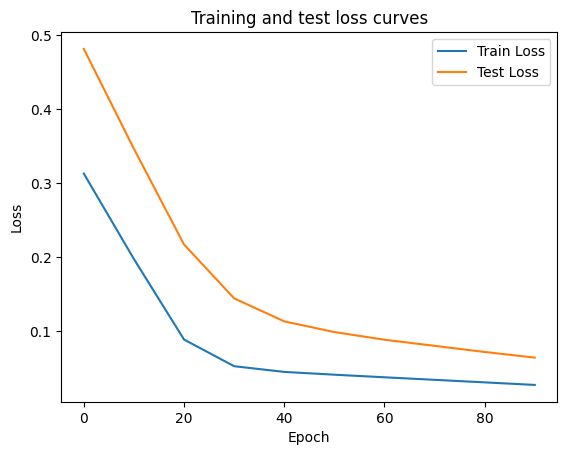

In [ ]:
plt.plot(epoch_count, np.array(torch.tensor(loss_values).cpu().numpy()), label= "Train Loss")
plt.plot(epoch_count, test_loss_values, label="Test Loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend()

In [ ]:
with torch.inference_mode():
  y_preds_new=model_0(X_test)

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.5784])),
             ('bias', tensor([0.3513], dtype=torch.float64))])

In [ ]:
weight, bias

(0.7, 0.3)

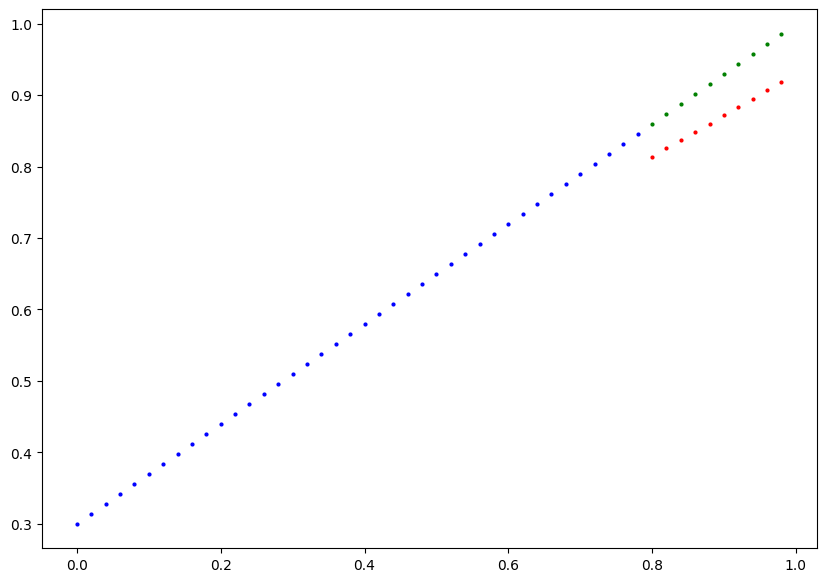

In [ ]:
plot_predictions(predictions=y_preds_new);

### Saving our PyTorch Model

In [ ]:
from pathlib import Path

# 1- Create model directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

# 2- Create model save path
MODEL_NAME="01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH=MODEL_PATH / MODEL_NAME

# 3- Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(),
           f=MODEL_SAVE_PATH)

Saving model to: models/01_pytorch_workflow_model_0.pth


In [ ]:
loaded_model_0=LinearRegressionModel()

loaded_model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])),
             ('bias', tensor([0.1288], dtype=torch.float64))])

### Putting it all together

In [ ]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

'2.11.0+cpu'

### Data

In [ ]:
weight=0.7
bias=0.3


start=0
end=1
step=0.02

X=torch.arange(start,end,step).unsqueeze(dim=1)
y=weight * X + bias
X[:10], y[:10]


(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [ ]:
train_split = int(0.8*len(X))
X_train, y_train = X[:train_split],y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]
len(X_train), len(y_train), len(X_test), len(y_test)


(40, 40, 10, 10)

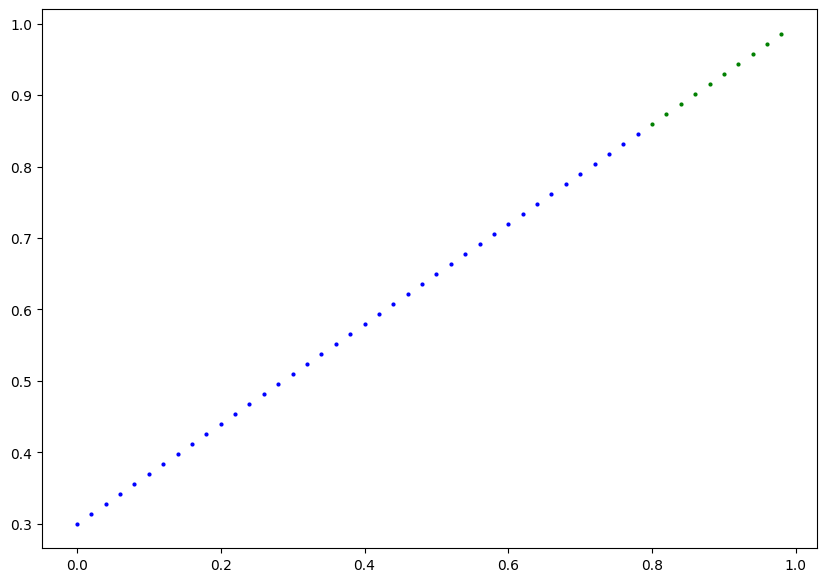

In [ ]:
plot_predictions(X_train,y_train,X_test,y_test)

###Building a PyTorch Linear Model

In [ ]:
class LinearRegressionModelV2(nn.Module):
  def __init__(self):
    super().__init__()
    # nn.Linear()
    self.linear_layer = nn.Linear(in_features=1,
                                  out_features=1)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.linear_layer(x)

torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()



(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [ ]:
next(model_1.parameters()).device


device(type='cpu')